# QPDK resonator test chip — 16 λ/4 resonators on two probelines (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/resonator_test_chip.py`
(`resonator_test_chip_python`) and its frozen netlist `resonator_test_chip_yaml.pic.yml`,
<https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** (gdsfactory 2024; depth-1 clone read
2026-11-03, never executed). Spec: `docs/designs/qpdk/resonator_test_chip.md`. Two straight west → east
probelines, 1000 µm apart, each between two launchers, each with eight shorted λ/4 CPW resonators
(`quarter_wave_resonator_coupled`, 6 meanders, 200 µm coupled section): bottom-line resonators hang below their
line, top-line ones (mirrored) above it. A loss / kinetic-inductance test chip; no qubits.

This notebook **rebuilds** the chip on the Quantcore PDK (not a replica); we distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 9.2 × 4.3 mm (the filled variant's chip edge) | the same 9.2 × 4.3 mm (it does not fit the 7.5 mm die), Quantcore die frame, device ID "QPDK-RTC"; Designer = source + (100, 1650) µm before centring |
| pads | QPDK `launcher` at the chip edge | `BondPad`s **100 µm** (`frame.pad_edge`) in from the die edge (`edge="auto"`; at the source position their etch touched the edge) |
| placement | — | the resonators centred between the pads: shifted **−106 µm** in x |
| substrate | Al on Si (εr 11.45) | sapphire 650 µm, εr 10.25 (frequencies are not the QPDK ones) |
| junctions | none | none |
| cheese | none in `resonator_test_chip_python` (QPDK's `filled_resonator_test_chip` adds a vortex fill; not this rebuild) | the **PDK band** (chip `cheese: "auto"`, at least 4 µm clear of 3/0) |
| resonators | — | kept: the 16 lengths `np.linspace(0.9, 1.275, 16) × 4000 µm` (3600 … 5100 µm in 100 µm steps, interleaved: even indices on the bottom line, odd on the top), the 1000 µm pitch, the 200 µm coupled sections, the short at each coupled section's west end, 6 meanders, the 16 µm resonator–probeline gap (4 µm KQC ground strip), CPW 10/6 µm, bend r 100 µm |

**Simplified:** the probelines run straight on the launcher axis (QPDK adds a small S-bend at each launcher, its
line sits 26 µm off the axis); each meander is the router's KQC `Meander` between the open end and the coupled
section (same total length and turn count); the README's "varied CPW widths and gaps" is not in the code or
YAML, so it is not reproduced. **Open ends:** each resonator starts at a 6 µm `CpweOpenEnd` gap, the same 6 µm
etched open end as QPDK's `open_start`.

**Fixed here:** the hanger couplers are anchored by position (`near=(x, y)` on the probeline) instead of an
arclength from the launcher, so the pad rule's 100 µm shift of the launchers leaves them at the source positions.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the four launchers, the two probelines, the sixteen open ends the resonators start from (this chip has no qubits), the sixteen λ/4 resonators on the probelines, and then the whole chip (sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `resonator_test_chip.v1.ipynb`; both save the same `resonator_test_chip.json`.

## Setup

The imports, the output folders and the switches. `_qpdk` holds the QPDK cell defaults shared by the QPDK
notebooks (launcher, hanger gap, the die box and the centring). `FULL_FAB = False` skips the fab-only corner
rounding in Fab 1 (`qcc mask` writes the full file). The segment pictures go to
`build/snapshots/resonator_test_chip/` (not kept in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
import numpy as np
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/resonator_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)
DX, DY = 100, 1650                               # Designer = QPDK source + (DX, DY), before centring

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**Junctions:** none on this chip (resonators only), so the PDK junction rule is not used.

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die, the bond pads, the readout line, then what
hangs on it, and the whole chip. A loss / kinetic-inductance test chip has no qubits, so segment 4 places the
resonators' open ends instead, and the coupling and control segments are empty (one sentence each). Each segment is
one cell with one picture of the chip so far (live, KLayout redraws after every cell). A route joins two ports, or a
port and a hanger on another route, so the probelines come before the resonators that hang on them. Coordinates are
QPDK's + (`DX`, `DY`) until the centring in Design 8.

| segment | what is placed here |
|---|---|
| 1 | the 9.2 × 4.3 mm die with the Quantcore frame (device ID QPDK-RTC) |
| 2 | the four launchers: each probeline between a west and an east launcher |
| 3 | the readout line: the two straight probelines, 1000 µm apart |
| 4 | no qubits: the sixteen 6 µm open ends the resonators start from |
| 5 | the sixteen λ/4 resonators, each shorted at the end of a 200 µm hanger on its probeline |
| 6 | the coupling: none besides each resonator's hanger (Design 5) |
| 7 | the control routing: none (no qubits, no flux or drive lines) |
| 8 | the whole chip: sim groups, the centring of the resonators, save |

## Design 1 · The die and its frame

The source's 9.2 × 4.3 mm chip with the Quantcore die frame and the device ID "QPDK-RTC". No `with_grid`: the
source has no cheese, so the build draws the PDK band.

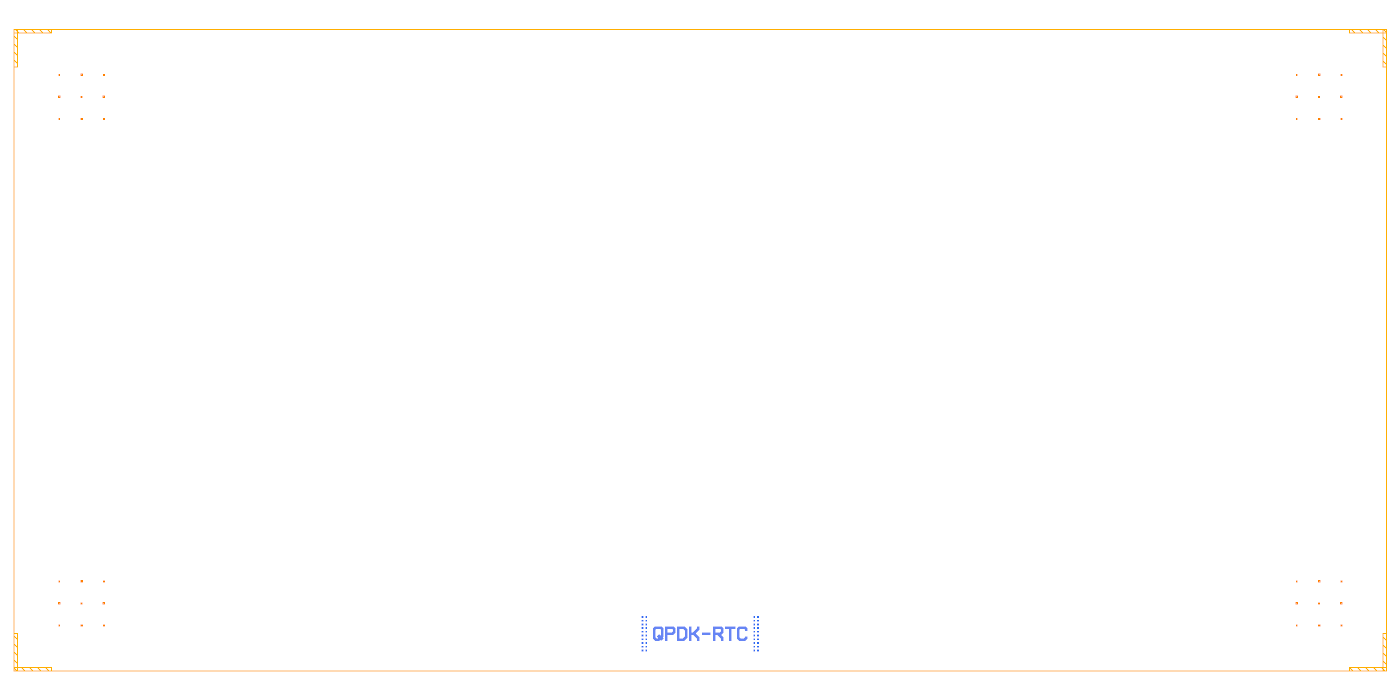

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/resonator_test_chip/s1_die.png')

In [5]:
W, H = 9200, 4300
d = Designer("resonator_test_chip", box=(0, 0, W, H), chip={"name_chip": "QPDK-RTC"}, live=LIVE)
layout_step(d, STEPS / "s1_die.png", size=(1400, 700), width=560)

## Design 2 · Bond pads: the four launchers and the pad rule

QPDK's `launcher` (a 200 × 200 µm wire-bond pad on a 200/110 µm CPW, a 100 µm taper to the 10/6 µm line) is a
KQC-style `BondPad` here (`QP.LAUNCHER`). **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge`
(100 µm) from the die edge. `edge="auto"` in `d.add` applies it: the pad keeps its position along the
nearest die edge (the source's launcher axis) and slides perpendicular to it until its etch ends 100 µm from
the edge. The lead routes to the circuit simply get longer; nothing else moves. The table shows each pad's
distance after the rule (✓ = 100 µm).
Four launchers: each probeline between a west and an east launcher, at y = 1650 and 2650 µm. QPDK draws them
with their etch at the chip edge; the rule moves them 100 µm in (each probeline is 200 µm shorter).

The first picture is the chip so far, the second zooms on the two west launchers.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PW_B | `BondPad` | w | 100.0 | ✓ |
| PE_B | `BondPad` | e | 100.0 | ✓ |
| PW_T | `BondPad` | w | 100.0 | ✓ |
| PE_T | `BondPad` | e | 100.0 | ✓ |

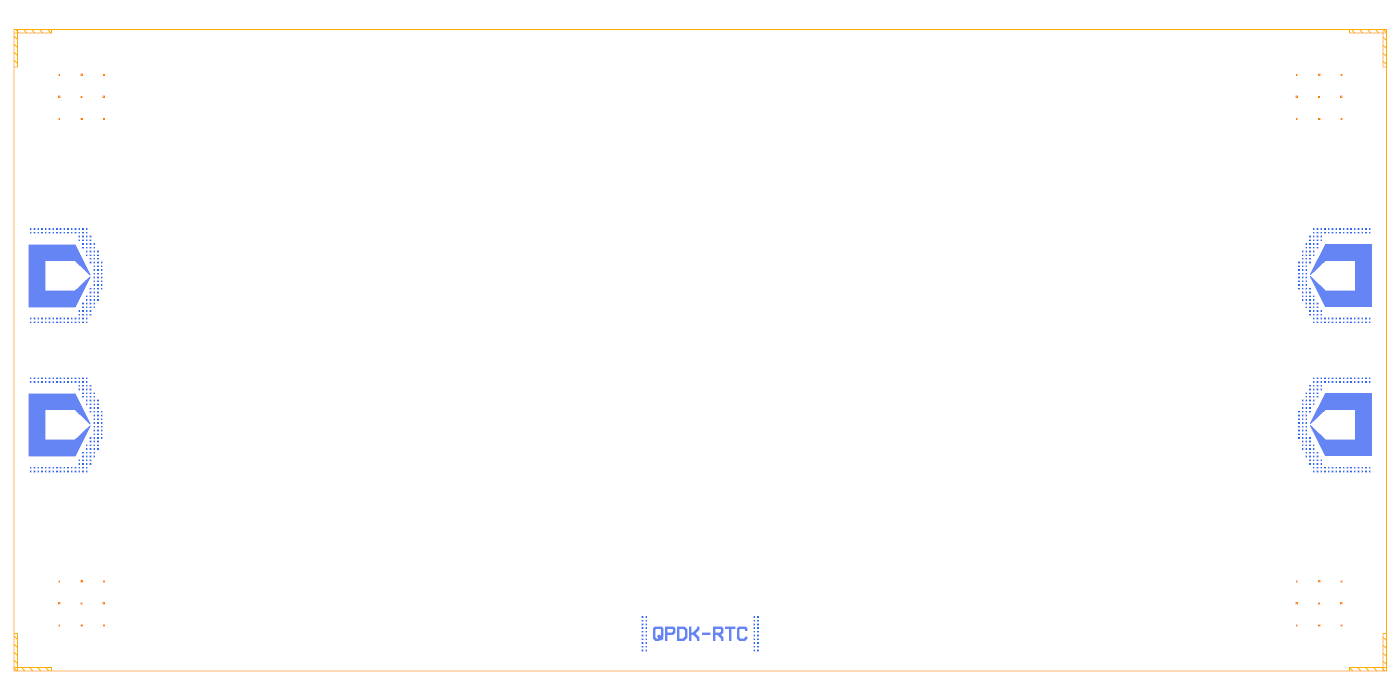

**On the chip so far:** 4 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `PW_B`, `PE_B`, `PW_T`, `PE_T`.

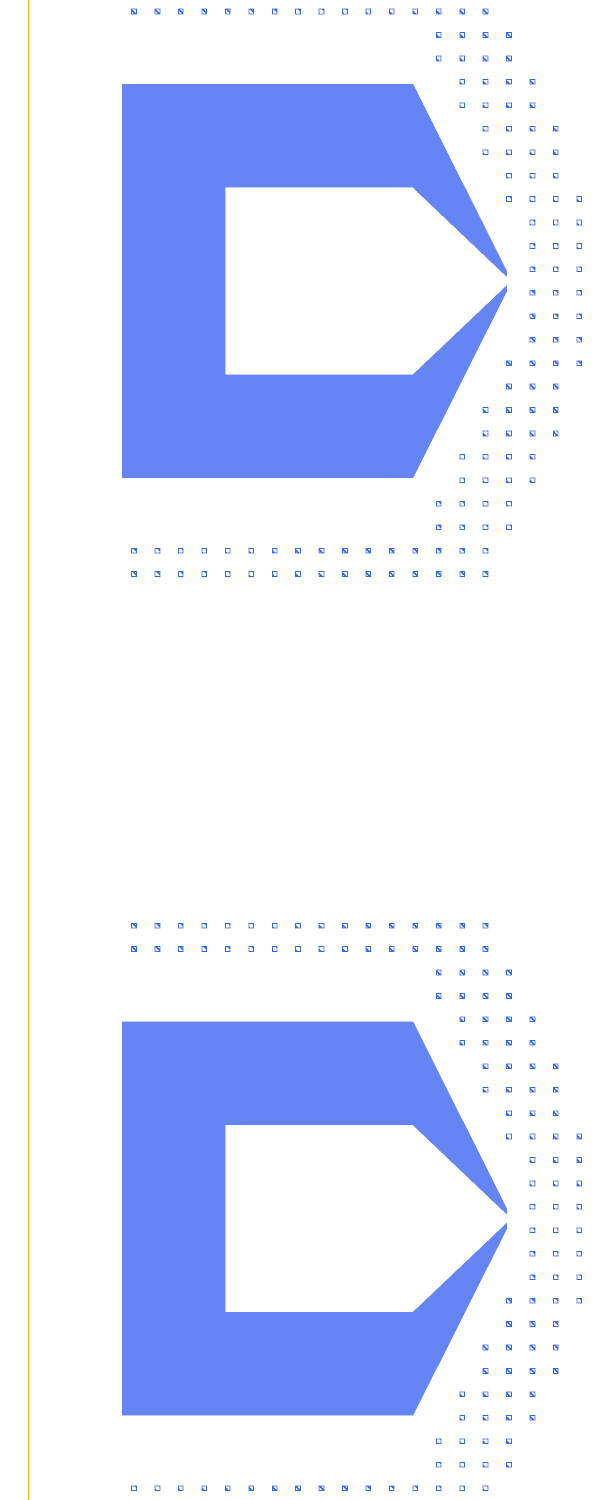

In [6]:
with d.batch():
    for line, y in (("B", DY), ("T", DY + 1000)):
        d.add(f"PW_{line}", "BondPad", at=(QP.LAUNCHER_DEPTH, y), rot=270, edge="auto", **QP.LAUNCHER)
        d.add(f"PE_{line}", "BondPad", at=(W - QP.LAUNCHER_DEPTH, y), rot=90, edge="auto", **QP.LAUNCHER)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "s2_pads.png", size=(1400, 700), width=560)
snap(d, STEPS / "2_pads.png", box=(-20, DY - 300, 600, DY + 1300), size=(600, 1500), width=260);

## Design 3 · Readout: the two probelines

**Probelines** straight from launcher to launcher on the launcher axis (r = 100 µm), at y = 1650 and 2650 µm (QPDK
adds a small S-bend at each launcher; not reproduced). They need nothing else on the chip, so they come first: the
resonators hang on them (Design 5). `lengths` are the sixteen resonator lengths `np.linspace(0.9, 1.275, 16) ×
4000 µm`; `LINES` gives each line its y, the side its resonators hang on, and its eight lengths (even indices on the
bottom line, odd on the top).

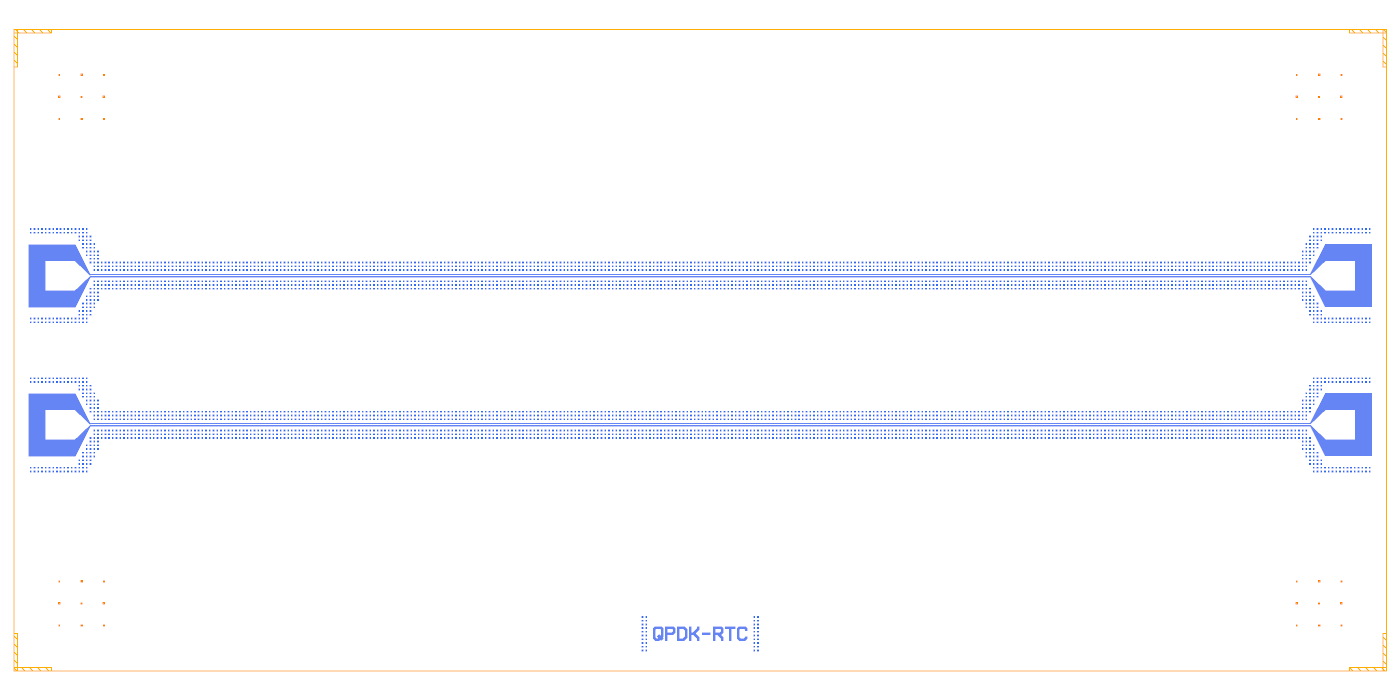

**On the chip so far:** 4 pads · 0 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** 2 route(s) `FL_B`, `FL_T`.

WindowsPath('build/snapshots/resonator_test_chip/s3_probelines.png')

In [7]:
lengths = np.linspace(0.9 * 4000, 1.275 * 4000, 16)
LINES = (("B", DY, "right", -1, lengths[0::2]), ("T", DY + 1000, "left", +1, lengths[1::2]))
with d.batch():
    for line, y, side, sgn, ls in LINES:
        fl = d.route(f"FL_{line}", f"PW_{line}.a", f"PE_{line}.a", r=QP.CPW_R)
layout_step(d, STEPS / "s3_probelines.png", size=(1400, 700), width=560)

## Design 4 · No qubits: the sixteen open ends

This chip has no qubits; what each resonator starts from is placed here. Sixteen 6 µm open ends (`CpweOpenEnd`, length 6 µm: QPDK's `open_start` etch), one per resonator, 1250 µm from
its probeline, 100 µm east of the coupled-section centre `xc = source 1000 k + 100` (k = 1 … 8). The resonator
lengths: even indices on the bottom line, odd on the top.

{'B': [3600, 3800, 4000, 4200, 4400, 4600, 4800, 5000], 'T': [3700, 3900, 4100, 4300, 4500, 4700, 4900, 5100]}


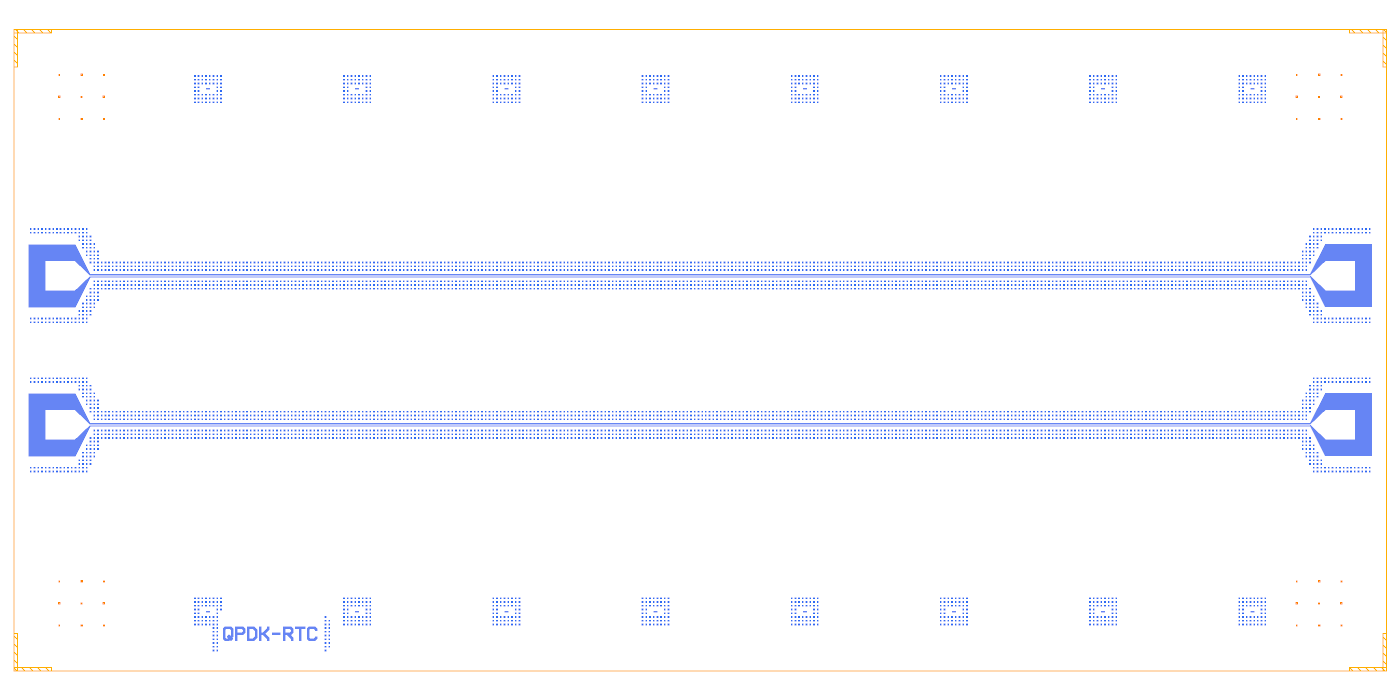

**On the chip so far:** 4 pads · 0 qubits · 16 other components · 2 routes · 0 declared couplings. **This step added** 16 component(s) `OE_B1`, `OE_B2`, `OE_B3`, `OE_B4`, `OE_B5`, `OE_B6`, `OE_B7`, `OE_B8` … (+8).

WindowsPath('build/snapshots/resonator_test_chip/s4_open_ends.png')

In [8]:
with d.batch():
    for line, y, side, sgn, ls in LINES:
        for k in range(1, 9):
            xc = DX + 1000 * k + 100                   # coupled-section centre (source 1000 k + 100)
            d.add(f"OE_{line}{k}", "CpweOpenEnd", at=(xc + 100, y + sgn * 1250), rot=90 * sgn, length=6)
print({line: [round(L) for L in ls] for line, _, _, _, ls in LINES})
layout_step(d, STEPS / "s4_open_ends.png", size=(1400, 700), width=560)

## Design 5 · Readout: the sixteen λ/4 resonators

From each open end a meander (6 turns, r = 75 µm) to a 200 µm coupled section hanging on its probeline —
`fl.hanger(near=(xc, y), length=200, side=..., ground_gap=4, direction="backward", end="short")`: centred at the
probeline point nearest (xc, y), a 4 µm ground strip (QPDK's 16 µm line-to-line gap), shorted at its west end
(`direction="backward"`) → λ/4. Anchored by position (`near=`), the couplers stay at the source positions although
the pad rule moved the launchers.

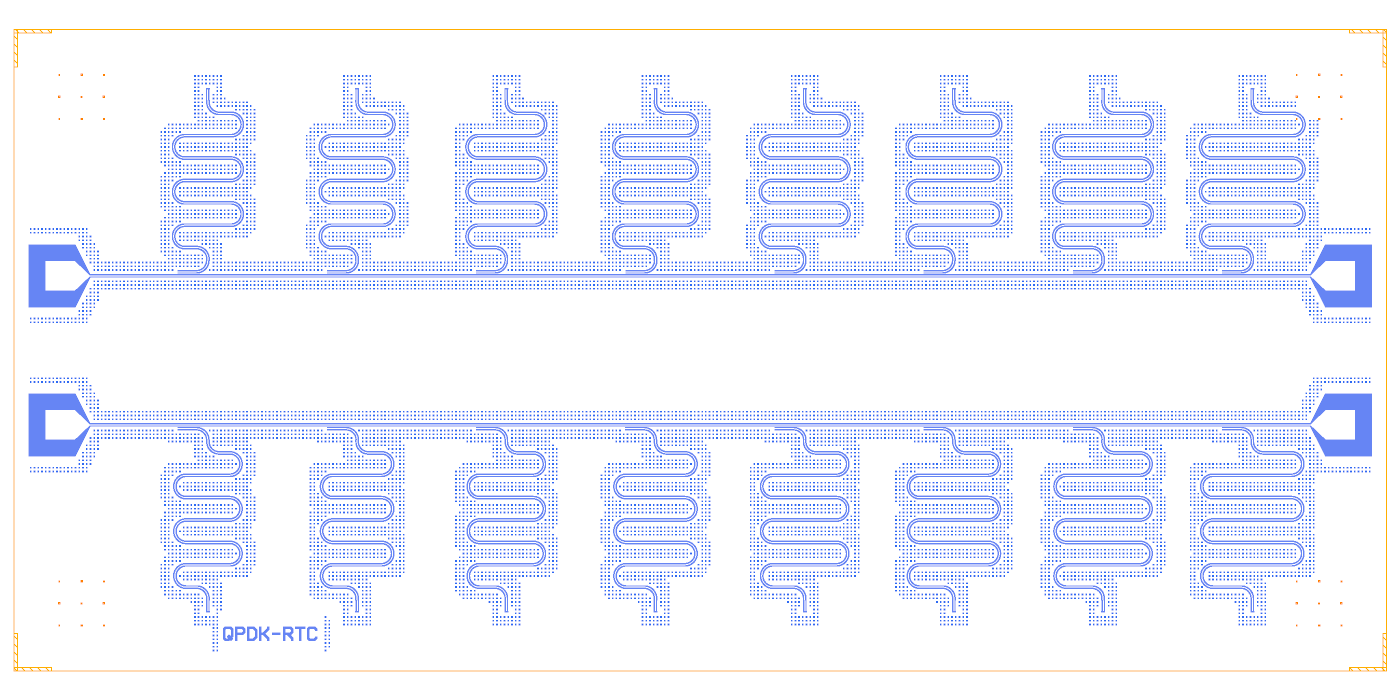

**On the chip so far:** 4 pads · 0 qubits · 16 other components · 18 routes · 0 declared couplings. **This step added** 16 route(s) `RB1`, `RB2`, `RB3`, `RB4`, `RB5`, `RB6`, `RB7`, `RB8` … (+8).

{'RB1': 3600.0, 'RB2': 3800.0, 'RB3': 4000.0, 'RB4': 4200.0, 'RB5': 4400.0, 'RB6': 4600.0, 'RB7': 4800.0, 'RB8': 5000.0, 'RT1': 3700.0, 'RT2': 3900.0, 'RT3': 4100.0, 'RT4': 4300.0, 'RT5': 4500.0, 'RT6': 4700.0, 'RT7': 4900.0, 'RT8': 5100.0}


In [9]:
with d.batch():
    for line, y, side, sgn, ls in LINES:
        fl = d[f"FL_{line}"]                         # the line's probeline (Design 3)
        for k, L in enumerate(ls, start=1):
            xc = DX + 1000 * k + 100
            d.route(f"R{line}{k}", f"OE_{line}{k}.a",
                    fl.hanger(near=(xc, y), length=200, side=side, ground_gap=QP.HANGER_GROUND_GAP,
                              direction="backward", end="short"),
                    meander=float(L), r=75).set(meanders=6)
layout_step(d, STEPS / "s5_resonators.png", size=(1400, 700), width=560)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if not k.startswith("FL")})

## Design 6 · Coupling: only the hangers

Each resonator couples to its own probeline through its coupled section (Design 5); nothing couples the resonators to
each other on purpose (they sit 1000 µm apart), so there is nothing to add here.

## Design 7 · Routing: no control lines

No qubits, so no flux, drive or charge lines.

## Design 8 · The whole chip: sim groups, the centring, save

**Sim groups:** one per probeline with its eight resonators and open ends (eigenmode only: a shorted λ/4 is ground in
a C-matrix; 200 µm margin).

**Centring.** With the pads at the die edge, the check measures the *circuit* (`QP.circuit_box`: every
instance and route except the pads and their lead routes) and `QP.center_circuit` shifts it to the die centre
when it is more than 50 µm off. Pads placed with `edge="auto"` follow the shift along their edge and stay
100 µm (`frame.pad_edge`) from it; hangers follow their feedline. The probelines run pad to pad, so they count as leads: the circuit box is the resonators', which sit 106 µm east
of the die centre in the source layout (coupled sections at 1000 k + 100 µm, meanders east of them).

**Save.** `save_design` writes the JSON and compares it with the file it replaces (the previous run's): the segments
above changed how the chip is built (both probelines now come before the resonators), not the chip, so it should say
*same design*; the file keeps the previous key order, so `git diff` stays empty.

circuit centring shift (µm): (-105.5, 0.0)


**Same design as before:** `examples/designs/qpdk/resonator_test_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer resonator_test_chip: 20 instances, 18 routes, live=False> → examples\designs\qpdk\resonator_test_chip.json


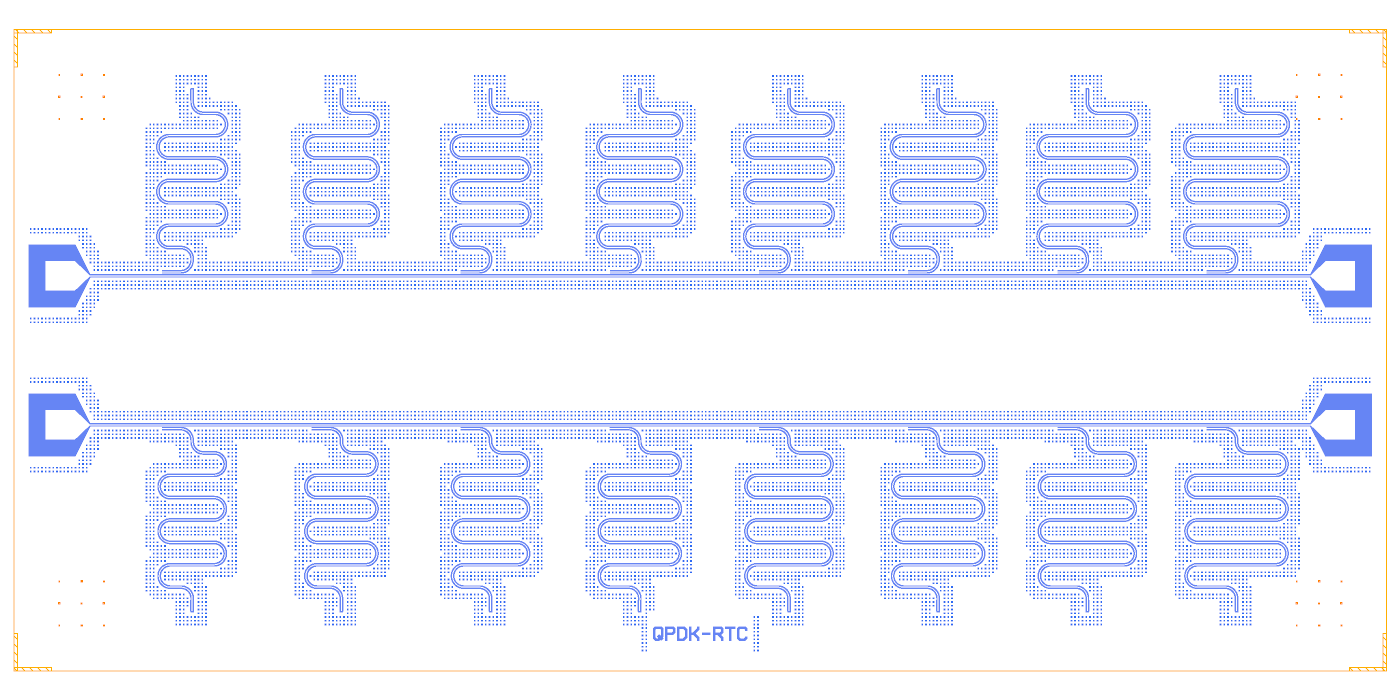

**On the chip so far:** 4 pads · 0 qubits · 16 other components · 18 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/resonator_test_chip/s8_chip.png')

In [10]:
for line in "BT":
    d.sim_group(f"LINE_{line}", [f"FL_{line}"] + [f"{p}{line}{k}" for k in range(1, 9) for p in ("R", "OE_")],
                margin_um=200, analyses=["eigenmode_epr"])
SHIFT = QP.center_circuit(d)
print("circuit centring shift (µm):", SHIFT)
rebuild(d)
DESIGN, same = save_design(d, OUT / "resonator_test_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "s8_chip.png", size=(1400, 700), width=560)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included, so a chip with launchers on one side reads
off-centre there) and the junction types.
Expected here (from the v1 run): no errors, no warnings and no PDK design warnings (the pads are 100 µm from the edge, no junctions).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
Each resonator: the open end, the meander and the coupled section form one λ/4 `TLres` (open at the `CpweOpenEnd`,
shorted at the coupled section's end) with a `HANGER` κ element to its probeline node; each probeline is a node
between its two 50 Ω pads.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('RB1', 'OE_B1', 'FL_B',)))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Linear circuits: the modes are the 8 λ/4 notches per line, with κ into the probeline. The source states no
targets (QPDK's README shows a SAX sweep from 4 to 10 GHz on Si). From the v1 run: 6.28–8.71 GHz on the bottom line, 6.16–8.48 GHz on the top, κ 0.10–0.27 MHz.

In [ ]:
groups = {f"LINE_{l}": [f"FL_{l}"] + [f"{p}{l}{k}" for k in range(1, 9) for p in ("R", "OE_")] for l in "BT"}
res = simulate_groups(d, groups, max_modes=8)
for g, r in res.items():
    display(Markdown(f"**{g}:**\n\n" + modes_md(r)))

## LOM 2 · The LOM in a plot

The same results as a picture: (a) the eight modes of each probeline (QuCat; squares are resonators), (b) the
dispersive-shift panel stays empty: no qubits, no χ.

In [ ]:
plot_lom(res, STEPS / "lom.png", title="resonator_test_chip: LOM per probeline")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. A resonator test chip sweeps the coupling quality factor with the coupled-section length: shorten RB1's from 200
to 150 µm keeping the end the meander arrives at in place (a fixed centre would pull that end into the route's bend). κ drops (roughly with the
square of the coupled length, so Q_c rises ≈ 1.8×) and f_r moves slightly (the coupled section is part of the
λ/4). Done on a copy (`design_copy`), so the design keeps QPDK's 200 µm.

In [ ]:
d2 = design_copy(DESIGN)
end = d2["RB1"].spec["to"]                    # keep the coupler end the meander arrives at (+x side) in place
d2["RB1"].set(to=dict(end, length=150, near=[end["near"][0] + 25, end["near"][1]]))
after = simulate_groups(d2, {"LINE_B": groups["LINE_B"]}, max_modes=8)
display(Markdown("**RB1 coupled section: 200 → 150 µm**\n\n"
                 + params_delta_md({"LINE_B": res["LINE_B"]}, after, keys=["RB1."])))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/qpdk/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One eigenmode / EPR job per probeline with its eight resonators (the probeline ends leave the box in 50 Ω, so each mode Q gives κ). A shorted λ/4 is ground in a C-matrix, so there is no Q3D job (as for KQC QualityFactor).
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). `FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/qpdk/fem/: solved results are kept here
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")   # the groups' own analysis: eigenmode only
display(Markdown(jobs_md(jobs_eig)))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "LINE_B", "eigenmode_epr", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: none here

The component step of the plugin is a Q3D C-matrix per group. A shorted λ/4 joins the ground plane at its far end,
so in a C-matrix it is part of ground: there is nothing to extract, and the sim groups ask for the eigenmode only
(as KQC's QualityFactor chip). The resonators' frequencies and κ come from the eigenmode (Simulate 3) and the driven
run (Simulate 4).

## Simulate 3 · Eigenmode simulation

Each probeline's box in HFSS eigenmode: the probeline's ends leave the box in 50 Ω, so each resonator mode's Q gives
its κ into the line (Q_c, the quantity this chip measures). With eight resonators per line, the job must solve at
least eight modes above the start frequency; Results 1 lists what it found.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the bottom probeline: each resonator is a notch, which is how this chip is
measured. The library cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option yet), so
`driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the eigenmode job's mesh seeds, the
adaptive-mesh frequency at the eigenmode's mode nearest RB1 (the LOM's f before the eigenmode is solved) and a fast
sweep from 0.4 GHz below to 0.2 GHz above it, which holds RB1's notch only.

In [ ]:
f_rb1 = res["LINE_B"].params.get("RB1.f_GHz")             # the LOM's RB1 frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "LINE_B", jobs_eig["LINE_B"][0], keep_eig["LINE_B"], f_guess=f_rb1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["LINE_B"]:
    display(Markdown(driven_md(keep_drv["LINE_B"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q (no junction: every p_J is 0), with the LOM's sixteen resonator frequencies as dashed lines. The tables below list
the modes.

In [ ]:
lom_r = {g: {m.label: m.f_GHz for m in r.modes if m.kind == "resonator"} for g, r in res.items()}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom={k: f for g in lom_r for k, f in lom_r[g].items()})
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

Each LOM resonator against the eigenmode it is: `match_modes` pairs them in order of frequency (the k-th lowest LOM
resonator with the k-th lowest chosen mode, Q > 100), so two close neighbours cannot swap. κ = f/Q of the
50 Ω-terminated box (Q here is the coupling Q plus the box's other losses). The driven run adds RB1's notch fit.

In [ ]:
fem_r = {g: match_modes(keep_eig.get(g), lom_r[g]) for g in res}
rows = []
for g, r in res.items():
    for m in r.modes:
        if m.kind != "resonator":
            continue
        e = fem_r[g].get(m.label)
        kap = "–" if m.kappa_MHz is None else f"{m.kappa_MHz:.3g}"
        rows.append(f"| {g} | `{m.label}` | {m.f_GHz:.4f} | {kap} | "
                    + (f"{e['f_GHz']:.4f} | {e['Q']:.3g} | {1e3 * e['f_GHz'] / e['Q']:.3g} |" if e else "– | – | – |"))
if any(fem_r.values()):
    display(Markdown("| line | resonator | LOM f (GHz) | LOM κ (MHz) | FEM f (GHz) | FEM Q | FEM κ = f/Q (MHz) |\n"
                     "|---|---|---|---|---|---|---|\n" + "\n".join(rows)))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would put each resonator's LOM f and κ next to its "
          "eigenmode f, Q and κ.")
if keep_drv["LINE_B"]:
    print("RB1, driven notch:", driven_values(keep_drv["LINE_B"], "RB1", f_rb1))

## Results 3 · FEM against the LOM

The LOM's f and κ of each resonator (LOM 1) next to the eigenmode's, with the difference in %. The LOM's λ/4 is the
drawn length on a CPW formula; the FEM adds the bends, the open end's fringe field and the coupled section's real
geometry, so expect an offset of a few per cent, the same sign for all sixteen.

In [ ]:
rows = []
for g, r in res.items():
    for m in r.modes:
        e = fem_r[g].get(m.label)
        if m.kind == "resonator" and e:
            rows += [(f"{m.label}.f_GHz", m.f_GHz, e["f_GHz"], "eigenmode"),
                     (f"{m.label}.kappa_MHz", m.kappa_MHz, 1e3 * e["f_GHz"] / e["Q"], "eigenmode, f/Q")]
if keep_drv["LINE_B"]:
    rows += [(k, res["LINE_B"].params.get(k), v, "driven S21 notch")
             for k, v in driven_values(keep_drv["LINE_B"], "RB1", f_rb1).items()]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts each resonator's LOM f and κ next to the "
          "eigenmode's (and RB1's driven notch), with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no targets, so this notebook sets one as an exercise: **RB1 at 8.60 GHz**, ≈ 110 MHz below where
the LOM puts it (from the v1 run: 8.711 GHz) and still above RB2 (8.25 GHz), so the line keeps its order. There is no
qubit, so `loop.feedback` (which tunes qubit–readout pairs) does not apply; the feedback is the first-order rule of a
λ/4: f ∝ 1/ℓ, so the new length is ℓ · f / f_target (≈ +47 µm here; the meander takes it, so lengthening is safe).
When an eigenmode is kept, the LOM is first scaled by FEM / LOM of RB1 (`SCALE`), so the step aims at the FEM value.
The target goes on a copy (`target_copy` → `build/resonator_test_chip_target.json`); the revisions are copies of it.

In [ ]:
F_T, F_TOL = 8.60, 0.001                         # the exercise target for RB1 and its tolerance (GHz)
DESIGN_T = target_copy(DESIGN, {"RB1": {"f_GHz": F_T}})
f_lom = lom_r["LINE_B"]["RB1"]
f_fem = (fem_r["LINE_B"].get("RB1") or {}).get("f_GHz")
SCALE = f_fem / f_lom if f_fem else 1.0          # FEM / LOM at the drawn length (1: the LOM alone)
L0 = float(d.data["routes"]["RB1"]["length"])
L1 = rule_step(L0, SCALE * f_lom, F_T, -1.0)
display(Markdown(f"**RB1:** now {SCALE * f_lom:.4f} GHz ({'FEM' if f_fem else 'LOM'}), target {F_T} ± {F_TOL} GHz → "
                 f"length {L0:.1f} → **{L1:.1f} µm** (f ∝ 1/ℓ)"))

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the length, its LOM runs (× `SCALE`), and the next step uses the
exponent of the last two points (a secant), until RB1 is within 1 MHz or `MAX_ITER` steps are made. With
`RUN_FEM = True` each revision's LINE_B eigenmode is exported to `build/jobs/rev<k>/` and solved (minutes each), and
the loop closes on the FEM's RB1.

In [ ]:
def f_rb1_of(k, it):
    """Revision it: RB1 k µm long; its frequency on the LOM (× SCALE), or from its own eigenmode with RUN_FEM."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["RB1"].set(meander=k)
    path = d2.save(Path("build") / f"resonator_test_chip_rev{it}.json")
    r = simulate_groups(d2, {"LINE_B": groups["LINE_B"]}, max_modes=8)["LINE_B"]
    lom_k = {m.label: m.f_GHz for m in r.modes if m.kind == "resonator"}
    if RUN_FEM:
        job = export_sims(path, ["LINE_B"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["LINE_B"]
        e = match_modes(keep, lom_k).get("RB1")
        if e:
            return e["f_GHz"], path
    return SCALE * lom_k["RB1"], path


history = rule_iterate(f_rb1_of, "RB1.f_GHz", "RB1.length", L0, F_T, F_TOL, -1.0, max_iter=MAX_ITER,
                       start=(SCALE * f_lom, DESIGN_T), fem=bool(RUN_FEM))
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `resonator_test_chip.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/qpdk/resonator_test_chip.json` rebuilds `build/resonator_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
No junction layers (none on the chip). The cheese source is `build`: the PDK band (the source has none), at least 4 µm clear of 3/0.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/resonator_test_chip.json`
writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip (compare QPDK's `resonator_test_chip.png`, shown last); resonator RB1 and its coupled section; the
shorted end of the coupled section; the open end; the die frame's south-west corner; and RB1's coupled section in
the **fab view** (the mask from Fab 1: 1/0 with the PDK cheese band, 3/0). Boxes are the source positions + the
centring shift.

In [ ]:
SX, SY = SHIFT


def box(x0, y0, x1, y1):                         # a source-frame box, moved with the centring shift
    return (x0 + SX, y0 + SY, x1 + SX, y1 + SY)


show_snapshot(d, OUT / "resonator_test_chip.png", size=(1800, 900), width=720)
show_snapshot(d, OUT / "resonator_test_chip_rb1.png", box=box(900, 300, 1700, 1750), size=(800, 1450), width=360)
show_snapshot(d, OUT / "resonator_test_chip_short.png", box=box(1000, 1580, 1300, 1680), size=(1500, 500), width=480)
show_snapshot(d, OUT / "resonator_test_chip_open.png", box=box(1200, 330, 1400, 470), width=300)
show_snapshot(d, OUT / "resonator_test_chip_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "resonator_test_chip_fab.oas", OUT / "resonator_test_chip_fab_rb1.png",
          box=box(950, 1450, 1450, 1750), size=(1000, 600), width=480);

**The original.** gdsfactory is not installed in this environment, so the source is not rebuilt here; QPDK's own
render is shown from the local clone when present.

In [ ]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "resonator_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/resonator_test_chip.png")

## Summary

| | |
|---|---|
| **matches the source** | the two probelines and their launchers, the 16 resonator lengths, the 1000 µm pitch, the 200 µm coupled sections with the 16 µm gap, shorted west ends, 6 meanders, the 6 µm open ends |
| **differs (PDK)** | the Quantcore die frame; pads 100 µm in from the edge; the resonators centred (−106 µm in x); couplers anchored by `near=`; sapphire; the PDK cheese band |
| **simplified** | straight probelines (no S-bends at the launchers); router meanders |
| **PDK design warnings** | none |
| layout | built in eight segments (die, launchers, probelines, open ends, resonators; no coupling and no control lines; the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (RB1 8.60 GHz): the λ/4 rule f ∝ 1/ℓ on RB1's length, iterated with a secant (LOM × FEM/LOM scale; eigenmode per revision with `RUN_FEM`) |
| open | the FEM jobs (eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |